# 46500 Probabilistic Methods in Wind Energy
## Mid-term Assignment: Lifetime Damage Accumulation for the Root Section of the Wind Turbine 


s253916 Natalia Slimak

---

In [134]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import scipy.optimize as optimize
import seaborn as sns
import os

In [135]:
# Load the provided data sets
wind_data = "HovsoreData_Sonic_100m_2004-2013.csv"
del_data = "ML_ExampleDataSet.xlsx"

# Outfput folder location for generated figures
output_figs = "figures/"
os.makedirs(output_figs, exist_ok=True)

# Read the data into pandas DataFrames
df_wind = pd.read_csv(wind_data)
df_del = pd.read_excel(del_data)

# Clean the data
df_wind = df_wind.dropna(subset=["Wsp","TI"])
df_wind = df_wind[(df_wind['Wsp'] > 0) & (df_wind['Wsp'] < 30) & (df_wind['TI'] > 0) & (df_wind['TI'] < 1)]

### Task 2: Determine the probability distribution of the wind climate uncertainty variable $X_W$ by analysing the wind data through bootstrapping, further incorporating a 1% uncertainty for windspeed measurement and 1% for the joint-distribution fit.

NOTES:
- $X_w$ - wind climate uncertainty factor

In [ ]:
# Windspeed (U) and turbulence intensity (TI) data
U, TI = df_wind['Wsp'].values, df_wind['TI'].values

In [ ]:
import numpy as np
from scipy import stats

def bootstrap_xw(U, block_days=None, Nbootstrap=5000, measurement_cov=0.01, joint_fit_cov=0.01, seed=1):
    rng = np.random.default_rng(seed)
    baseline_mean_u = np.mean(U)
    N = len(U)
    BootstrapMeans = np.empty(Nbootstrap)

    # IID bootstrap (no block structure)
    if block_days is None:
        for i in range(Nbootstrap):
            bootstrap_sample = rng.choice(U, size=N, replace=True)
            measurement_factor = (1.0 + rng.normal(0, measurement_cov))
            BootstrapMeans[i] = (np.mean(bootstrap_sample) * measurement_factor)

    # Block bootstrap
    else:
        block_size = int(block_days * 144) # 144 records/day
        for i in range(Nbootstrap):
            bootstrap_series = []
            while len(bootstrap_series) < N:
                start = rng.integers(0, N)
                idx = (np.arange(start, start + block_size) % N)
                bootstrap_series.extend(U[idx])
            bootstrap_series = np.asarray(bootstrap_series[:N])
            measurement_factor = (1.0 + rng.normal(0, measurement_cov))
            BootstrapMeans[i] = (np.mean(bootstrap_series)* measurement_factor)
    Xw_bootstrap = BootstrapMeans / baseline_mean_u
    joint_fit_factor = (1.0 + rng.normal(0, joint_fit_cov, Nbootstrap))
    Xw = Xw_bootstrap * joint_fit_factor

    return Xw[Xw > 0]

In [149]:
Xw_random = bootstrap_xw(U, block_days=None)
Xw_7d = bootstrap_xw(U, block_days=7)
Xw_30d = bootstrap_xw(U, block_days=30)
Xw_90d = bootstrap_xw(U, block_days=90)
Xw_365d = bootstrap_xw(U, block_days=365)

In [ ]:
datasets = {
    "IID": Xw_random,
    "7-day": Xw_7d,
    "30-day": Xw_30d,
    "90-day": Xw_90d,
    "365-day": Xw_365d
}

for name, xw in datasets.items():
    cov = np.std(xw) / np.mean(xw)
    print(f"{name:8s}: " f"CoV = {100*cov:.2f}%")

IID     : CoV = 1.42%
7-day   : CoV = 1.92%
30-day  : CoV = 2.33%
90-day  : CoV = 2.93%
365-day : CoV = 2.42%


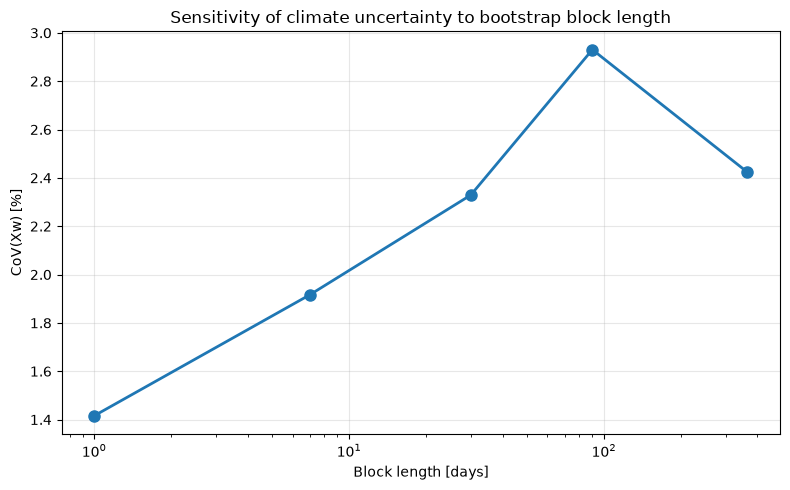

In [170]:
block_lengths = [1, 7, 30, 90, 365]

covs = [
    np.std(Xw_random)/np.mean(Xw_random)*100,
    np.std(Xw_7d)/np.mean(Xw_7d)*100,
    np.std(Xw_30d)/np.mean(Xw_30d)*100,
    np.std(Xw_90d)/np.mean(Xw_90d)*100,
    np.std(Xw_365d)/np.mean(Xw_365d)*100
]

plt.figure(figsize=(8,5))
plt.plot(block_lengths, covs, 'o-', lw=2, ms=8)
plt.xscale('log')
plt.xlabel('Block length [days]')
plt.ylabel('CoV(Xw) [%]')
plt.title('Sensitivity of climate uncertainty ''to bootstrap block length')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(output_figs + "2.1_CoV_Xw_block_lengths.png", dpi=300)
plt.show()


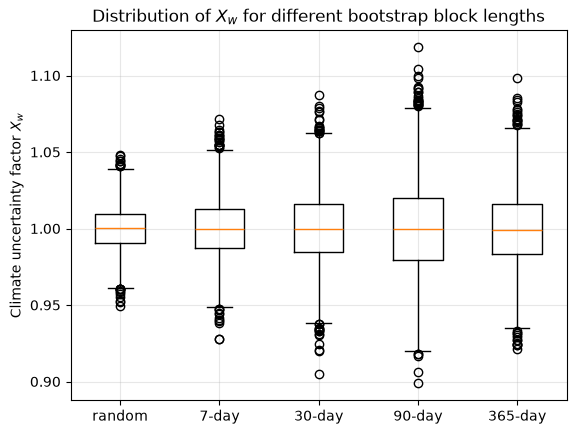

In [160]:
plt.boxplot([Xw_random, Xw_7d, Xw_30d, Xw_90d, Xw_365d])
plt.xticks([1, 2, 3, 4, 5], ['random', '7-day', '30-day', '90-day', '365-day'])
plt.ylabel('Climate uncertainty factor $X_w$')
plt.title('Distribution of $X_w$ for different bootstrap block lengths')
plt.grid(True, alpha=0.3)
plt.savefig(output_figs + "2.2_boxplot_Xw_block_lengths.png", dpi=300)

In [163]:
# Fit Normal distribution
Xw_mean_365d, Xw_std_365d = stats.norm.fit(Xw_365d)
Xw_cov_365d = Xw_std_365d / Xw_mean_365d

print(f"Xw mean = {Xw_mean_365d:.4f}")
print(f"Xw std  = {Xw_std_365d:.4f}")
print(f"Xw CoV  = {100*Xw_cov_365d:.2f}%")

Xw mean = 0.9997
Xw std  = 0.0242
Xw CoV  = 2.42%


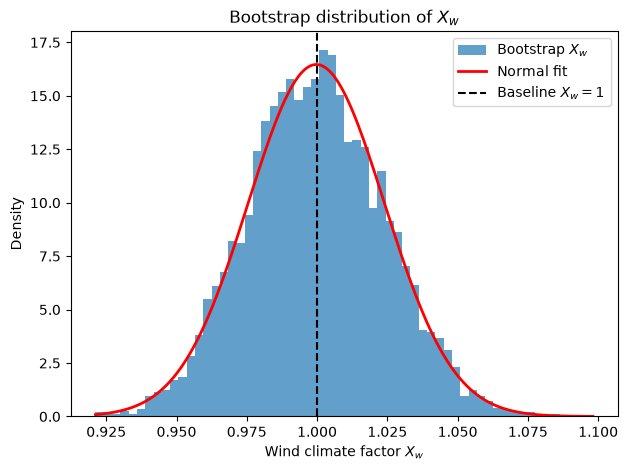

In [172]:
# Visual comparison: original wind sample and the resulting X_w distribution.
xw_grid = np.linspace(Xw_365d.min(), Xw_365d.max(), 300)
plt.hist(Xw_365d, bins=60, density=True, alpha=0.7, label='Bootstrap $X_w$')
plt.plot(xw_grid, stats.norm.pdf(xw_grid, Xw_mean_365d, Xw_std_365d), 'r-', lw=2, label='Normal fit')
plt.axvline(1.0, color='k', ls='--', label='Baseline $X_w=1$')
plt.xlabel(r'Wind climate factor $X_w$')
plt.ylabel('Density')
plt.title('Bootstrap distribution of $X_w$')
plt.legend()
plt.tight_layout()
plt.savefig(output_figs + "2.3_Xw_distribution.png", dpi=300)
plt.show()